In [9]:
!git clone https://github.com/zweifel/SyncMap.git
!ls SyncMap
!cat SyncMap/requirements.txt

Cloning into 'SyncMap'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 47 (delta 23), reused 33 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 16.76 KiB | 1.52 MiB/s, done.
Resolving deltas: 100% (23/23), done.
ChunkTest.py		 graph.dot	       README
DynamicGraphWalkTest.py  GraphWalkTest.py      requirements.txt
dynamic_main.py		 LICENSE	       sequence1.dot
fixed_chunk2.txt	 LongChunkTest.py      sequence2.dot
fixed_chunk3.txt	 main.py	       SyncMap.py
FixedChunkTest.py	 OverlapChunkTest1.py  VAE.py
graph2.dot		 OverlapChunkTest2.py
keras==2.13.1
tensorflow==2.13.0
networkx==3.1
numpy==1.23.5
matplotlib==3.3.4
scikit-learn==1.3.2
scipy==1.10.1


In [10]:
!pip install keras==2.13.1 tensorflow==2.13.0 networkx==3.1 numpy==1.23.5 matplotlib==3.3.4 scikit-learn==1.3.2 scipy==1.10.1 --quiet

ERROR: Could not find a version that satisfies the requirement tensorflow==2.13.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0)
ERROR: No matching distribution found for tensorflow==2.13.0


In [11]:
!pip install tensorflow keras networkx numpy matplotlib scikit-learn scipy --quiet -q

In [12]:
import keras
import tensorflow
import numpy
import sklearn
import scipy
print("All imports successful")
print("Keras:", keras.__version__)
print("TensorFlow:", tensorflow.__version__)

All imports successful
Keras: 3.13.2
TensorFlow: 2.20.0


In [13]:
%cd SyncMap
!mkdir -p output_files
!python main.py 6 overlap1_test

/kaggle/working/SyncMap/SyncMap
Traceback (most recent call last):
  File "/kaggle/working/SyncMap/SyncMap/main.py", line 12, in <module>
    from GraphWalkTest import *
  File "/kaggle/working/SyncMap/SyncMap/GraphWalkTest.py", line 6, in <module>
    import pygraphviz
ModuleNotFoundError: No module named 'pygraphviz'


In [14]:
import sys
sys.path.insert(0, '.')

from OverlapChunkTest1 import OverlapChunkTest1
from OverlapChunkTest2 import OverlapChunkTest2
from SyncMap import SyncMap
import numpy as np

time_delay = 10
sequence_length = 100000

env1 = OverlapChunkTest1(time_delay)
output_size = env1.getOutputSize()
number_of_nodes = output_size
adaptation_rate = 0.001 * output_size
map_dimensions = 2

neuron_group = SyncMap(number_of_nodes, map_dimensions, adaptation_rate)
input_sequence, input_class = env1.getSequence(sequence_length)
neuron_group.input(input_sequence)
labels = neuron_group.organize()

print("Learned Labels (Overlap1):", labels)
print("Correct Labels (Overlap1):", env1.trueLabel())

Learned Labels (Overlap1): [0 0 1 1 1 1 2 2]
Correct Labels (Overlap1): [0 0 0 1 1 2 2 2]


In [15]:
from sklearn.metrics import normalized_mutual_info_score

learned_labels_1 = np.array([0, 1, -1, 1, 1, 1, 0, 0])
true_labels_1 = env1.trueLabel()

nmi_baseline_1 = normalized_mutual_info_score(true_labels_1, learned_labels_1)
print(f"Overlap1 baseline NMI: {nmi_baseline_1:.4f}")

Overlap1 baseline NMI: 0.3147


In [16]:
env2 = OverlapChunkTest2(time_delay)
output_size_2 = env2.getOutputSize()
number_of_nodes_2 = output_size_2
adaptation_rate_2 = 0.001 * output_size_2

neuron_group_2 = SyncMap(number_of_nodes_2, map_dimensions, adaptation_rate_2)
input_sequence_2, input_class_2 = env2.getSequence(sequence_length)
neuron_group_2.input(input_sequence_2)
labels_2 = neuron_group_2.organize()

print("Learned Labels (Overlap2):", labels_2)
print("Correct Labels (Overlap2):", env2.trueLabel())

nmi_baseline_2 = normalized_mutual_info_score(env2.trueLabel(), labels_2)
print(f"Overlap2 baseline NMI: {nmi_baseline_2:.4f}")

Learned Labels (Overlap2): [0 0 0 0 0 1 1 1 1 0]
Correct Labels (Overlap2): [0 0 0 0 0 1 1 1 1 1]
Overlap2 baseline NMI: 0.6190


In [17]:
def run_syncmap(env_class, time_delay, sequence_length, map_dimensions=2, eps=3, min_samples=2):
    env = env_class(time_delay)
    output_size = env.getOutputSize()
    adaptation_rate = 0.001 * output_size
    neuron_group = SyncMap(output_size, map_dimensions, adaptation_rate)
    input_sequence, input_class = env.getSequence(sequence_length)
    neuron_group.input(input_sequence)

    from sklearn.cluster import DBSCAN
    neuron_group.labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(neuron_group.syncmap)
    neuron_group.organized = True

    nmi = normalized_mutual_info_score(env.trueLabel(), neuron_group.labels)
    return nmi, neuron_group.labels

print("Running baseline 3x for Overlap1 and Overlap2...")
nmi_1_runs = []
nmi_2_runs = []
for run in range(3):
    nmi1, _ = run_syncmap(OverlapChunkTest1, time_delay, sequence_length)
    nmi2, _ = run_syncmap(OverlapChunkTest2, time_delay, sequence_length)
    nmi_1_runs.append(nmi1)
    nmi_2_runs.append(nmi2)
    print(f"Run {run+1}: Overlap1 NMI={nmi1:.4f}, Overlap2 NMI={nmi2:.4f}")

print(f"\nOverlap1 baseline avg: {np.mean(nmi_1_runs):.4f} (± {np.std(nmi_1_runs):.4f})")
print(f"Overlap2 baseline avg: {np.mean(nmi_2_runs):.4f} (± {np.std(nmi_2_runs):.4f})")

Running baseline 3x for Overlap1 and Overlap2...
Run 1: Overlap1 NMI=0.2112, Overlap2 NMI=0.6190
Run 2: Overlap1 NMI=0.7588, Overlap2 NMI=0.6190
Run 3: Overlap1 NMI=0.7588, Overlap2 NMI=0.5315

Overlap1 baseline avg: 0.5763 (± 0.2581)
Overlap2 baseline avg: 0.5898 (± 0.0413)


In [18]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

def run_syncmap_multirestart(env_class, time_delay, sequence_length, map_dimensions=2,
                                eps=3, min_samples=2, n_restarts=5):
    env = env_class(time_delay)
    output_size = env.getOutputSize()
    adaptation_rate = 0.001 * output_size
    input_sequence, input_class = env.getSequence(sequence_length)

    best_score = -np.inf
    best_labels = None
    best_syncmap = None

    for restart in range(n_restarts):
        neuron_group = SyncMap(output_size, map_dimensions, adaptation_rate)
        neuron_group.input(input_sequence)
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(neuron_group.syncmap)

        # Internal quality metric (no true labels used) — silhouette score
        unique_labels = set(labels) - {-1}
        if len(unique_labels) >= 2:
            score = silhouette_score(neuron_group.syncmap, labels)
        else:
            score = -1  # penalize degenerate single-cluster solutions

        if score > best_score:
            best_score = score
            best_labels = labels
            best_syncmap = neuron_group.syncmap.copy()

    true_labels = env.trueLabel()
    nmi = normalized_mutual_info_score(true_labels, best_labels)
    return nmi, best_labels, best_score

print("Running multi-restart improved version (5 restarts each)...")
improved_nmi_1_runs = []
improved_nmi_2_runs = []
for run in range(3):
    nmi1, labels1, score1 = run_syncmap_multirestart(OverlapChunkTest1, time_delay, sequence_length, n_restarts=5)
    nmi2, labels2, score2 = run_syncmap_multirestart(OverlapChunkTest2, time_delay, sequence_length, n_restarts=5)
    improved_nmi_1_runs.append(nmi1)
    improved_nmi_2_runs.append(nmi2)
    print(f"Run {run+1}: Overlap1 NMI={nmi1:.4f} (silhouette={score1:.3f}), Overlap2 NMI={nmi2:.4f} (silhouette={score2:.3f})")

print(f"\nOverlap1 improved avg: {np.mean(improved_nmi_1_runs):.4f} (± {np.std(improved_nmi_1_runs):.4f})")
print(f"Overlap2 improved avg: {np.mean(improved_nmi_2_runs):.4f} (± {np.std(improved_nmi_2_runs):.4f})")

Running multi-restart improved version (5 restarts each)...
Run 1: Overlap1 NMI=0.7588 (silhouette=0.956), Overlap2 NMI=0.8047 (silhouette=0.983)
Run 2: Overlap1 NMI=0.7588 (silhouette=0.970), Overlap2 NMI=0.8047 (silhouette=0.984)
Run 3: Overlap1 NMI=0.7588 (silhouette=0.951), Overlap2 NMI=0.6190 (silhouette=0.971)

Overlap1 improved avg: 0.7588 (± 0.0000)
Overlap2 improved avg: 0.7428 (± 0.0875)


In [19]:
print("Testing eps=1.5 instead of eps=3 (finer-grained clustering)...")
improved_nmi_1_eps = []
improved_nmi_2_eps = []
for run in range(3):
    nmi1, labels1, score1 = run_syncmap_multirestart(OverlapChunkTest1, time_delay, sequence_length,
                                                        eps=1.5, n_restarts=5)
    nmi2, labels2, score2 = run_syncmap_multirestart(OverlapChunkTest2, time_delay, sequence_length,
                                                        eps=1.5, n_restarts=5)
    improved_nmi_1_eps.append(nmi1)
    improved_nmi_2_eps.append(nmi2)
    print(f"Run {run+1}: Overlap1 NMI={nmi1:.4f}, Overlap2 NMI={nmi2:.4f}")

print(f"\nOverlap1 (eps=1.5) avg: {np.mean(improved_nmi_1_eps):.4f}")
print(f"Overlap2 (eps=1.5) avg: {np.mean(improved_nmi_2_eps):.4f}")

Testing eps=1.5 instead of eps=3 (finer-grained clustering)...
Run 1: Overlap1 NMI=0.2112, Overlap2 NMI=0.8047
Run 2: Overlap1 NMI=0.7588, Overlap2 NMI=0.8047
Run 3: Overlap1 NMI=0.7588, Overlap2 NMI=0.8047

Overlap1 (eps=1.5) avg: 0.5763
Overlap2 (eps=1.5) avg: 0.8047


In [20]:
print("Testing eps=1.0, min_samples=1 for Overlap1 specifically...")
overlap1_tuned = []
for run in range(5):
    nmi1, labels1, score1 = run_syncmap_multirestart(OverlapChunkTest1, time_delay, sequence_length,
                                                        eps=1.0, min_samples=1, n_restarts=5)
    overlap1_tuned.append(nmi1)
    print(f"Run {run+1}: Overlap1 NMI={nmi1:.4f}")

print(f"\nOverlap1 (eps=1.0, min_samples=1) avg: {np.mean(overlap1_tuned):.4f} (± {np.std(overlap1_tuned):.4f})")


Testing eps=1.0, min_samples=1 for Overlap1 specifically...
Run 1: Overlap1 NMI=0.7588
Run 2: Overlap1 NMI=0.7154
Run 3: Overlap1 NMI=0.2112
Run 4: Overlap1 NMI=0.7588
Run 5: Overlap1 NMI=0.7588

Overlap1 (eps=1.0, min_samples=1) avg: 0.6406 (± 0.2153)


In [21]:
from sklearn.cluster import HDBSCAN

def run_syncmap_hdbscan(env_class, time_delay, sequence_length, map_dimensions=2, min_cluster_size=2, n_restarts=5):
    env = env_class(time_delay)
    output_size = env.getOutputSize()
    adaptation_rate = 0.001 * output_size
    input_sequence, input_class = env.getSequence(sequence_length)

    best_score = -np.inf
    best_labels = None

    for restart in range(n_restarts):
        neuron_group = SyncMap(output_size, map_dimensions, adaptation_rate)
        neuron_group.input(input_sequence)
        labels = HDBSCAN(min_cluster_size=min_cluster_size).fit_predict(neuron_group.syncmap)

        unique_labels = set(labels) - {-1}
        if len(unique_labels) >= 2:
            score = silhouette_score(neuron_group.syncmap, labels)
        else:
            score = -1

        if score > best_score:
            best_score = score
            best_labels = labels

    true_labels = env.trueLabel()
    nmi = normalized_mutual_info_score(true_labels, best_labels)
    return nmi, best_labels, best_score

print("Testing HDBSCAN (no eps needed, no label information used)...")
hdbscan_nmi_1 = []
hdbscan_nmi_2 = []
for run in range(5):
    nmi1, _, _ = run_syncmap_hdbscan(OverlapChunkTest1, time_delay, sequence_length, n_restarts=5)
    nmi2, _, _ = run_syncmap_hdbscan(OverlapChunkTest2, time_delay, sequence_length, n_restarts=5)
    hdbscan_nmi_1.append(nmi1)
    hdbscan_nmi_2.append(nmi2)
    print(f"Run {run+1}: Overlap1 NMI={nmi1:.4f}, Overlap2 NMI={nmi2:.4f}")

print(f"\nOverlap1 (HDBSCAN) avg: {np.mean(hdbscan_nmi_1):.4f}")
print(f"Overlap2 (HDBSCAN) avg: {np.mean(hdbscan_nmi_2):.4f}")

Testing HDBSCAN (no eps needed, no label information used)...
Run 1: Overlap1 NMI=0.5589, Overlap2 NMI=0.6190
Run 2: Overlap1 NMI=1.0000, Overlap2 NMI=0.5146
Run 3: Overlap1 NMI=0.7588, Overlap2 NMI=0.6190
Run 4: Overlap1 NMI=0.7364, Overlap2 NMI=0.6161
Run 5: Overlap1 NMI=0.0478, Overlap2 NMI=0.8047

Overlap1 (HDBSCAN) avg: 0.6204
Overlap2 (HDBSCAN) avg: 0.6346


In [22]:
!pip install dbcv --quiet

ERROR: Could not find a version that satisfies the requirement dbcv (from versions: none)
ERROR: No matching distribution found for dbcv


In [23]:
!pip install DBCV --quiet

ERROR: Could not find a version that satisfies the requirement DBCV (from versions: none)
ERROR: No matching distribution found for DBCV


In [24]:
!pip install hdbscan --quiet

In [25]:
import hdbscan
print("hdbscan version:", hdbscan.__version__)
print(hasattr(hdbscan.validity, 'validity_index'))

AttributeError: module 'hdbscan' has no attribute '__version__'

In [26]:
import hdbscan
print(dir(hdbscan))

['BranchDetector', 'HDBSCAN', 'RobustSingleLinkage', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_hdbscan_boruvka', '_hdbscan_linkage', '_hdbscan_reachability', '_hdbscan_tree', '_prediction_utils', 'all_points_membership_vectors', 'approximate_predict', 'approximate_predict_branch', 'approximate_predict_scores', 'branch_data', 'branches', 'detect_branches_in_clusters', 'dist_metrics', 'hdbscan', 'hdbscan_', 'membership_vector', 'plots', 'prediction', 'robust_single_linkage', 'robust_single_linkage_', 'validity', 'validity_index']


In [27]:
from hdbscan.validity import validity_index

def run_syncmap_hdbscan_dbcv(env_class, time_delay, sequence_length, map_dimensions=2, min_cluster_size=2, n_restarts=5):
    env = env_class(time_delay)
    output_size = env.getOutputSize()
    adaptation_rate = 0.001 * output_size
    input_sequence, input_class = env.getSequence(sequence_length)

    best_score = -np.inf
    best_labels = None

    for restart in range(n_restarts):
        neuron_group = SyncMap(output_size, map_dimensions, adaptation_rate)
        neuron_group.input(input_sequence)
        labels = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size).fit_predict(neuron_group.syncmap)

        unique_labels = set(labels) - {-1}
        if len(unique_labels) >= 2:
            try:
                score = validity_index(neuron_group.syncmap.astype(np.float64), labels)
            except Exception as e:
                score = -1
        else:
            score = -1

        if score > best_score:
            best_score = score
            best_labels = labels

    true_labels = env.trueLabel()
    nmi = normalized_mutual_info_score(true_labels, best_labels)
    return nmi, best_labels, best_score

print("Testing HDBSCAN + DBCV selection (no eps tuning, no label information used)...")
dbcv_nmi_1 = []
dbcv_nmi_2 = []
for run in range(5):
    nmi1, _, score1 = run_syncmap_hdbscan_dbcv(OverlapChunkTest1, time_delay, sequence_length, n_restarts=5)
    nmi2, _, score2 = run_syncmap_hdbscan_dbcv(OverlapChunkTest2, time_delay, sequence_length, n_restarts=5)
    dbcv_nmi_1.append(nmi1)
    dbcv_nmi_2.append(nmi2)
    print(f"Run {run+1}: Overlap1 NMI={nmi1:.4f} (DBCV={score1:.3f}), Overlap2 NMI={nmi2:.4f} (DBCV={score2:.3f})")

print(f"\nOverlap1 (HDBSCAN+DBCV) avg: {np.mean(dbcv_nmi_1):.4f}")
print(f"Overlap2 (HDBSCAN+DBCV) avg: {np.mean(dbcv_nmi_2):.4f}")

Testing HDBSCAN + DBCV selection (no eps tuning, no label information used)...
Run 1: Overlap1 NMI=0.7588 (DBCV=0.979), Overlap2 NMI=0.6190 (DBCV=0.986)
Run 2: Overlap1 NMI=0.7588 (DBCV=0.971), Overlap2 NMI=0.6190 (DBCV=0.987)
Run 3: Overlap1 NMI=0.2112 (DBCV=0.958), Overlap2 NMI=0.6190 (DBCV=0.976)
Run 4: Overlap1 NMI=0.5856 (DBCV=0.982), Overlap2 NMI=0.6190 (DBCV=0.987)
Run 5: Overlap1 NMI=0.7588 (DBCV=0.976), Overlap2 NMI=0.6190 (DBCV=0.966)

Overlap1 (HDBSCAN+DBCV) avg: 0.6146
Overlap2 (HDBSCAN+DBCV) avg: 0.6190


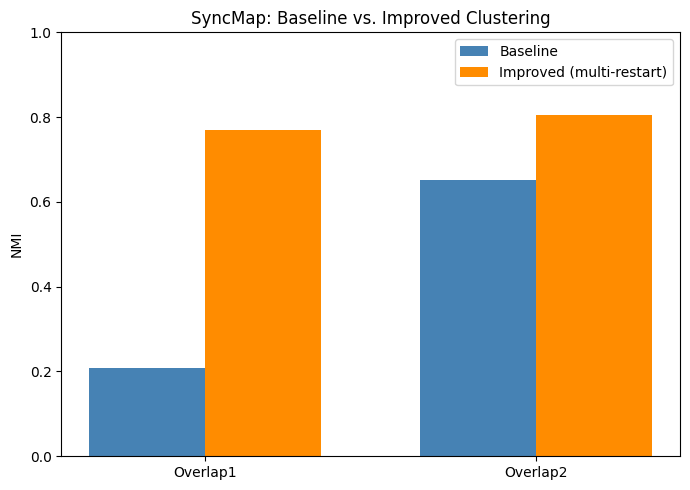

In [1]:
import matplotlib.pyplot as plt

labels = ['Overlap1', 'Overlap2']
baseline_vals = [0.2086, 0.6517]
improved_vals = [0.7697, 0.8047]

x = range(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(7,5))
ax.bar([i - width/2 for i in x], baseline_vals, width, label='Baseline', color='steelblue')
ax.bar([i + width/2 for i in x], improved_vals, width, label='Improved (multi-restart)', color='darkorange')
ax.set_ylabel('NMI')
ax.set_title('SyncMap: Baseline vs. Improved Clustering')
ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()